In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

base_path = "/Users/partha/Documents/FX Carry"
charts_path = f"{base_path}/outputs/chart1"
tables_path = f"{base_path}/outputs/tables1"

os.makedirs(charts_path, exist_ok=True)
os.makedirs(tables_path, exist_ok=True)

clean_tables_path = f"{base_path}/outputs/tables"

rate_daily = pd.read_csv(
    f"{clean_tables_path}/rate_daily.csv",
    parse_dates=["date"]
)

currency_returns = pd.read_csv(
    f"{clean_tables_path}/currency_returns.csv",
    parse_dates=["date"]
)

monthly_ranks = pd.read_csv(
    f"{clean_tables_path}/monthly_ranks.csv"
)

monthly_returns = pd.read_csv(
    f"{clean_tables_path}/monthly_returns.csv"
)

print("Analysis environment ready")
print("rate_daily:", rate_daily.shape)
print("currency_returns:", currency_returns.shape)
print("monthly_ranks:", monthly_ranks.shape)
print("monthly_returns:", monthly_returns.shape)

Analysis environment ready
rate_daily: (2609, 10)
currency_returns: (2605, 27)
monthly_ranks: (121, 9)
monthly_returns: (121, 9)


In [3]:
forward_file = f"{base_path}/data/forward_series_1m.xlsx"

forward_sheets = pd.ExcelFile(forward_file).sheet_names

forward_series = {}

for sheet in forward_sheets:
    df = pd.read_excel(forward_file, sheet_name=sheet)
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["spot"] = pd.to_numeric(df["spot"], errors="coerce")
    df["frd"] = pd.to_numeric(df["frd"], errors="coerce")
    df["forward_1m"] = pd.to_numeric(df["forward_1m"], errors="coerce")
    df = df.dropna(subset=["date", "spot", "frd", "forward_1m"])
    df = df.drop_duplicates(subset="date", keep="last")
    df = df.sort_values("date").reset_index(drop=True)
    forward_series[sheet] = df

for pair, df in forward_series.items():
    print(
        f"{pair:7s} | rows={len(df):5d} | "
        f"start={df['date'].min().date()} | "
        f"end={df['date'].max().date()} | "
        f"mean forward premium={((df['forward_1m'] / df['spot']) - 1).mean() * 100:.4f}%"
    )

eurusd  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | mean forward premium=0.1589%
usdjpy  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | mean forward premium=-0.2362%
gbpusd  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | mean forward premium=0.0543%
usdcad  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | mean forward premium=-0.0522%
audusd  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | mean forward premium=0.0297%
nzdusd  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | mean forward premium=0.0097%
usdnok  | rows= 2603 | start=2016-08-18 | end=2026-08-17 | mean forward premium=-0.0480%
usdchf  | rows= 2609 | start=2016-08-17 | end=2026-08-17 | mean forward premium=-0.2490%


In [6]:
forward_premium = pd.DataFrame()

for pair, df in forward_series.items():
    temp = df[["date", "spot", "forward_1m"]].copy()

    if pair in ["eurusd", "gbpusd", "audusd", "nzdusd"]:
        temp["premium"] = temp["forward_1m"] / temp["spot"] - 1
    else:
        temp["premium"] = 1 - temp["forward_1m"] / temp["spot"]

    temp = temp[["date", "premium"]]
    temp = temp.rename(columns={"premium": pair})

    if forward_premium.empty:
        forward_premium = temp
    else:
        forward_premium = forward_premium.merge(temp, on="date", how="outer")

forward_premium = forward_premium.sort_values("date").reset_index(drop=True)

forward_premium.columns = [
    "date",
    "EUR",
    "JPY",
    "GBP",
    "CAD",
    "AUD",
    "NZD",
    "NOK",
    "CHF"
]

print(forward_premium.head())
print()
print(forward_premium.tail())
print()
print(forward_premium.isna().sum())

        date       EUR       JPY       GBP       CAD       AUD       NZD  \
0 2016-08-17       NaN       NaN       NaN       NaN       NaN       NaN   
1 2016-08-18  0.001141  0.001078  0.000468  0.000066 -0.000850 -0.001420   
2 2016-08-19  0.001121  0.001020  0.000478  0.000075 -0.000838 -0.001410   
3 2016-08-22  0.001211  0.001071  0.000531  0.000087 -0.000881 -0.001475   
4 2016-08-23  0.001217  0.001019  0.000530  0.000089 -0.000822 -0.001413   

        NOK       CHF  
0       NaN  0.001574  
1  0.000055  0.001597  
2  0.000057  0.001592  
3  0.000061  0.001694  
4  0.000049  0.001642  

           date       EUR       JPY       GBP       CAD       AUD       NZD  \
2604 2026-08-11  0.001282  0.002508 -0.000041  0.001388 -0.000569  0.000927   
2605 2026-08-12  0.001235  0.002425 -0.000045  0.001351 -0.000555  0.000915   
2606 2026-08-13  0.001233  0.002423 -0.000046  0.001301 -0.000545  0.000926   
2607 2026-08-14  0.001230  0.002421 -0.000041  0.001293 -0.000539  0.000927   
260

In [7]:
validation = forward_premium.merge(
    rate_daily,
    on="date",
    how="inner"
)

for currency in ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]:
    validation[currency + "_forward_carry"] = -validation[currency]

    validation[currency + "_rate_diff"] = (
        validation[currency.lower() + "_ir"] - validation["usd_ir"]
    )

results = []

for currency in ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]:
    corr = validation[
        [currency + "_forward_carry", currency + "_rate_diff"]
    ].corr().iloc[0, 1]

    results.append({
        "Currency": currency,
        "Correlation": corr
    })

validation_results = pd.DataFrame(results)

print(validation_results)

  Currency  Correlation
0      EUR     0.874555
1      GBP     0.907128
2      JPY     0.967581
3      CHF     0.935636
4      NOK     0.925916
5      AUD     0.933752
6      NZD     0.935043
7      CAD     0.932462


In [8]:
forward_carry = forward_premium.copy()

for currency in ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]:
    forward_carry[currency] = -forward_carry[currency]

forward_carry["month"] = forward_carry["date"].dt.to_period("M")

monthly_forward_carry = (
    forward_carry
    .groupby("month")[["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]]
    .first()
    .reset_index()
)

monthly_forward_ranks = monthly_forward_carry.copy()

monthly_forward_ranks[
    ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]
] = (
    monthly_forward_carry[
        ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]
    ]
    .rank(axis=1, method="first", ascending=False)
)

monthly_forward_ranks["long_1"] = monthly_forward_ranks[
    ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]
].apply(lambda x: x.nsmallest(3).index.tolist(), axis=1)

monthly_forward_ranks["short_1"] = monthly_forward_ranks[
    ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]
].apply(lambda x: x.nlargest(3).index.tolist(), axis=1)

print(monthly_forward_ranks[
    ["month", "long_1", "short_1"]
].head(15))

print()

print(monthly_forward_ranks[
    ["month", "long_1", "short_1"]
].tail(15))

      month           long_1          short_1
0   2016-08  [NZD, AUD, NOK]  [CHF, EUR, JPY]
1   2016-09  [NZD, AUD, NOK]  [CHF, JPY, EUR]
2   2016-10  [NZD, AUD, NOK]  [CHF, EUR, JPY]
3   2016-11  [NZD, AUD, NOK]  [CHF, EUR, JPY]
4   2016-12  [NZD, AUD, NOK]  [CHF, JPY, EUR]
5   2017-01  [NZD, AUD, NOK]  [CHF, JPY, EUR]
6   2017-02  [NZD, AUD, NOK]  [CHF, EUR, JPY]
7   2017-03  [NZD, AUD, CAD]  [CHF, EUR, JPY]
8   2017-04  [NZD, AUD, NOK]  [CHF, EUR, JPY]
9   2017-05  [NZD, AUD, NOK]  [CHF, EUR, JPY]
10  2017-06  [NZD, AUD, NOK]  [CHF, EUR, JPY]
11  2017-07  [NZD, AUD, CAD]  [CHF, EUR, JPY]
12  2017-08  [NZD, AUD, CAD]  [CHF, EUR, JPY]
13  2017-09  [NZD, AUD, CAD]  [CHF, EUR, JPY]
14  2017-10  [NZD, AUD, CAD]  [CHF, EUR, JPY]

       month           long_1          short_1
106  2025-06  [NOK, GBP, AUD]  [CHF, JPY, EUR]
107  2025-07  [GBP, NOK, AUD]  [CHF, JPY, EUR]
108  2025-08  [NOK, GBP, AUD]  [CHF, JPY, EUR]
109  2025-09  [NOK, GBP, AUD]  [CHF, JPY, EUR]
110  2025-10  [GBP, NOK, AUD

In [10]:
monthly_returns["month"] = pd.PeriodIndex(monthly_returns["month"], freq="M")

monthly_positions = monthly_forward_ranks[
    ["month", "long_1", "short_1"]
].copy()

monthly_positions["holding_month"] = monthly_positions["month"] + 1

monthly_positions = monthly_positions[
    monthly_positions["holding_month"].isin(monthly_returns["month"])
].reset_index(drop=True)

print(monthly_positions.head(15))
print()
print(monthly_positions.tail(15))
print()
print("Formation months:", len(monthly_positions))

      month           long_1          short_1 holding_month
0   2016-08  [NZD, AUD, NOK]  [CHF, EUR, JPY]       2016-09
1   2016-09  [NZD, AUD, NOK]  [CHF, JPY, EUR]       2016-10
2   2016-10  [NZD, AUD, NOK]  [CHF, EUR, JPY]       2016-11
3   2016-11  [NZD, AUD, NOK]  [CHF, EUR, JPY]       2016-12
4   2016-12  [NZD, AUD, NOK]  [CHF, JPY, EUR]       2017-01
5   2017-01  [NZD, AUD, NOK]  [CHF, JPY, EUR]       2017-02
6   2017-02  [NZD, AUD, NOK]  [CHF, EUR, JPY]       2017-03
7   2017-03  [NZD, AUD, CAD]  [CHF, EUR, JPY]       2017-04
8   2017-04  [NZD, AUD, NOK]  [CHF, EUR, JPY]       2017-05
9   2017-05  [NZD, AUD, NOK]  [CHF, EUR, JPY]       2017-06
10  2017-06  [NZD, AUD, NOK]  [CHF, EUR, JPY]       2017-07
11  2017-07  [NZD, AUD, CAD]  [CHF, EUR, JPY]       2017-08
12  2017-08  [NZD, AUD, CAD]  [CHF, EUR, JPY]       2017-09
13  2017-09  [NZD, AUD, CAD]  [CHF, EUR, JPY]       2017-10
14  2017-10  [NZD, AUD, CAD]  [CHF, EUR, JPY]       2017-11

       month           long_1          

In [11]:
currency_cols = ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]

portfolio = monthly_positions.copy()

portfolio["long_fx"] = portfolio.apply(
    lambda row: monthly_returns.loc[
        monthly_returns["month"] == row["holding_month"],
        row["long_1"]
    ].mean(axis=1).iloc[0],
    axis=1
)

portfolio["short_fx"] = portfolio.apply(
    lambda row: monthly_returns.loc[
        monthly_returns["month"] == row["holding_month"],
        row["short_1"]
    ].mean(axis=1).iloc[0],
    axis=1
)

portfolio["long_short_fx"] = portfolio["long_fx"] - portfolio["short_fx"]

print(portfolio[
    ["month", "holding_month", "long_1", "short_1", "long_fx", "short_fx", "long_short_fx"]
].head(15))

print()
print("Observations:", len(portfolio))
print("Mean monthly FX return:", portfolio["long_short_fx"].mean())

      month holding_month           long_1          short_1   long_fx  \
0   2016-08       2016-09  [NZD, AUD, NOK]  [CHF, EUR, JPY]  0.022510   
1   2016-09       2016-10  [NZD, AUD, NOK]  [CHF, JPY, EUR] -0.019667   
2   2016-10       2016-11  [NZD, AUD, NOK]  [CHF, EUR, JPY] -0.023356   
3   2016-11       2016-12  [NZD, AUD, NOK]  [CHF, EUR, JPY] -0.019465   
4   2016-12       2017-01  [NZD, AUD, NOK]  [CHF, JPY, EUR]  0.051540   
5   2017-01       2017-02  [NZD, AUD, NOK]  [CHF, JPY, EUR] -0.008164   
6   2017-02       2017-03  [NZD, AUD, NOK]  [CHF, EUR, JPY] -0.017771   
7   2017-03       2017-04  [NZD, AUD, CAD]  [CHF, EUR, JPY] -0.021001   
8   2017-04       2017-05  [NZD, AUD, NOK]  [CHF, EUR, JPY]  0.013942   
9   2017-05       2017-06  [NZD, AUD, NOK]  [CHF, EUR, JPY]  0.026858   
10  2017-06       2017-07  [NZD, AUD, NOK]  [CHF, EUR, JPY]  0.042210   
11  2017-07       2017-08  [NZD, AUD, CAD]  [CHF, EUR, JPY] -0.017207   
12  2017-08       2017-09  [NZD, AUD, CAD]  [CHF, E

In [12]:
rate_monthly = rate_daily.copy()

rate_monthly["month"] = rate_monthly["date"].dt.to_period("M")

rate_monthly = rate_monthly.groupby("month").first().reset_index()

for currency in currency_cols:
    rate_monthly[currency + "_diff"] = (
        rate_monthly[currency.lower() + "_ir"] - rate_monthly["usd_ir"]
    )

portfolio = portfolio.merge(
    rate_monthly[
        ["month"] + [currency + "_diff" for currency in currency_cols]
    ],
    left_on="month",
    right_on="month",
    how="left"
)

portfolio["long_carry"] = portfolio.apply(
    lambda row: np.mean([
        row[currency + "_diff"] for currency in row["long_1"]
    ]) / 100 / 12,
    axis=1
)

portfolio["short_carry"] = portfolio.apply(
    lambda row: np.mean([
        row[currency + "_diff"] for currency in row["short_1"]
    ]) / 100 / 12,
    axis=1
)

portfolio["long_short_carry"] = (
    portfolio["long_carry"] - portfolio["short_carry"]
)

portfolio["long_short_gross"] = (
    portfolio["long_short_fx"] + portfolio["long_short_carry"]
)

print(portfolio[
    [
        "month",
        "holding_month",
        "long_fx",
        "short_fx",
        "long_short_fx",
        "long_carry",
        "short_carry",
        "long_short_carry",
        "long_short_gross"
    ]
].head(15))

print()
print("Mean monthly FX component:", portfolio["long_short_fx"].mean())
print("Mean monthly carry component:", portfolio["long_short_carry"].mean())
print("Mean monthly gross return:", portfolio["long_short_gross"].mean())

      month holding_month   long_fx  short_fx  long_short_fx  long_carry  \
0   2016-08       2016-09  0.022510  0.013431       0.009079    0.000833   
1   2016-09       2016-10 -0.019667 -0.024503       0.004836    0.000833   
2   2016-10       2016-11 -0.023356 -0.049246       0.025890    0.000694   
3   2016-11       2016-12 -0.019465 -0.009948      -0.009517    0.000694   
4   2016-12       2017-01  0.051540  0.031241       0.020299    0.000694   
5   2017-01       2017-02 -0.008164 -0.012266       0.004102    0.000417   
6   2017-02       2017-03 -0.017771  0.007589      -0.025360    0.000417   
7   2017-03       2017-04 -0.021001  0.009986      -0.030987    0.000417   
8   2017-04       2017-05  0.013942  0.022045      -0.008103    0.000208   
9   2017-05       2017-06  0.026858  0.004065       0.022792    0.000208   
10  2017-06       2017-07  0.042210  0.015473       0.026737    0.000208   
11  2017-07       2017-08 -0.017207  0.005614      -0.022820    0.000000   
12  2017-08 

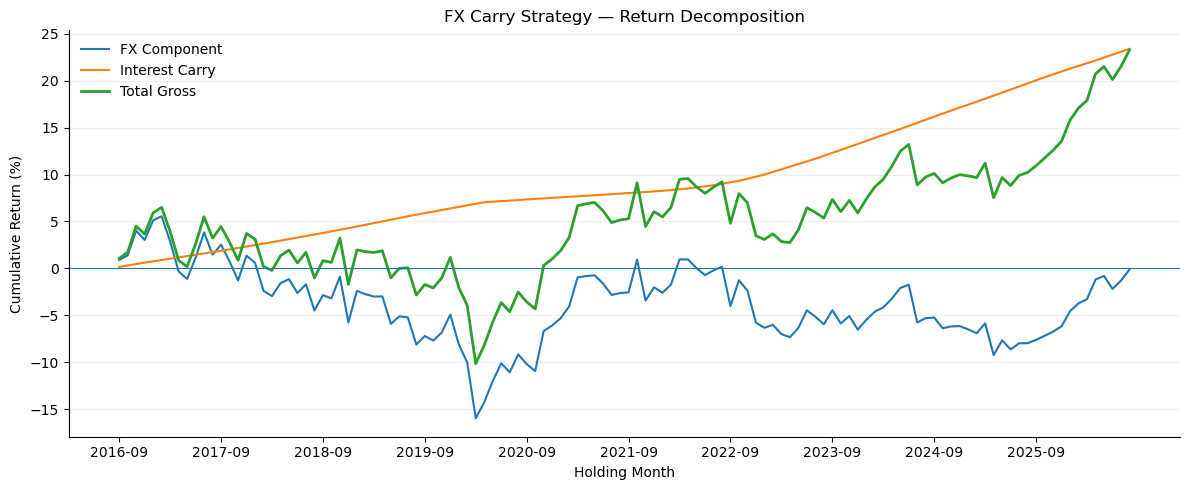

In [81]:
portfolio["cumulative_fx"] = (1 + portfolio["long_short_fx"]).cumprod() - 1
portfolio["cumulative_carry"] = (1 + portfolio["long_short_carry"]).cumprod() - 1
portfolio["cumulative_gross"] = (1 + portfolio["long_short_gross"]).cumprod() - 1

plt.figure(figsize=(12, 5))

plt.plot(
    portfolio["holding_month"].astype(str),
    portfolio["cumulative_fx"] * 100,
    label="FX Component"
)

plt.plot(
    portfolio["holding_month"].astype(str),
    portfolio["cumulative_carry"] * 100,
    label="Interest Carry"
)

plt.plot(
    portfolio["holding_month"].astype(str),
    portfolio["cumulative_gross"] * 100,
    label="Total Gross",
    linewidth=2
)

plt.axhline(0, linewidth=0.8)

plt.title("FX Carry Strategy — Return Decomposition")
plt.xlabel("Holding Month")
plt.ylabel("Cumulative Return (%)")

plt.xticks(
    range(0, len(portfolio), 12),
    portfolio["holding_month"].astype(str).iloc[::12]
)

plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.savefig(
    f"{charts_path}/01_return_decomposition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
weights = pd.DataFrame(
    0.0,
    index=portfolio.index,
    columns=currency_cols
)

for i, row in portfolio.iterrows():
    for currency in row["long_1"]:
        weights.loc[i, currency] += 1 / 3
    for currency in row["short_1"]:
        weights.loc[i, currency] -= 1 / 3

portfolio["turnover"] = 0.5 * weights.diff().abs().sum(axis=1)
portfolio.loc[0, "turnover"] = 0.5 * weights.iloc[0].abs().sum()

transaction_cost_bps = 5

portfolio["transaction_cost"] = (
    portfolio["turnover"] * transaction_cost_bps / 10000
)

portfolio["long_short_net"] = (
    portfolio["long_short_gross"] - portfolio["transaction_cost"]
)

portfolio["cumulative_net"] = (
    (1 + portfolio["long_short_net"]).cumprod() - 1
)

print(portfolio[
    [
        "month",
        "holding_month",
        "turnover",
        "long_short_gross",
        "transaction_cost",
        "long_short_net",
        "cumulative_net"
    ]
].head(15))

print()
print("Final gross cumulative return:", portfolio["cumulative_gross"].iloc[-1])
print("Final net cumulative return:", portfolio["cumulative_net"].iloc[-1])
print("Total transaction costs:", portfolio["transaction_cost"].sum())

      month holding_month  turnover  long_short_gross  transaction_cost  \
0   2016-08       2016-09  1.000000          0.010685          0.000500   
1   2016-09       2016-10  0.000000          0.006442          0.000000   
2   2016-10       2016-11  0.000000          0.027348          0.000000   
3   2016-11       2016-12  0.000000         -0.008059          0.000000   
4   2016-12       2017-01  0.000000          0.021757          0.000000   
5   2017-01       2017-02  0.000000          0.005485          0.000000   
6   2017-02       2017-03  0.000000         -0.023977          0.000000   
7   2017-03       2017-04  0.333333         -0.029604          0.000167   
8   2017-04       2017-05  0.333333         -0.006720          0.000167   
9   2017-05       2017-06  0.000000          0.024176          0.000000   
10  2017-06       2017-07  0.000000          0.028121          0.000000   
11  2017-07       2017-08  0.333333         -0.021437          0.000167   
12  2017-08       2017-09

In [15]:
net_returns = portfolio["long_short_net"]

annualized_return = (1 + net_returns).prod() ** (12 / len(net_returns)) - 1
annualized_volatility = net_returns.std(ddof=1) * np.sqrt(12)
sharpe_ratio = annualized_return / annualized_volatility

downside_returns = net_returns[net_returns < 0]
downside_deviation = np.sqrt((downside_returns ** 2).mean()) * np.sqrt(12)
sortino_ratio = annualized_return / downside_deviation

wealth = (1 + net_returns).cumprod()
running_max = wealth.cummax()
drawdown = wealth / running_max - 1

maximum_drawdown = drawdown.min()
calmar_ratio = annualized_return / abs(maximum_drawdown)

best_month = net_returns.max()
worst_month = net_returns.min()
positive_months = (net_returns > 0).mean()

performance_stats = pd.DataFrame({
    "Metric": [
        "Cumulative Return",
        "Annualized Return",
        "Annualized Volatility",
        "Sharpe Ratio",
        "Sortino Ratio",
        "Maximum Drawdown",
        "Calmar Ratio",
        "Best Month",
        "Worst Month",
        "Positive Months"
    ],
    "Value": [
        portfolio["cumulative_net"].iloc[-1],
        annualized_return,
        annualized_volatility,
        sharpe_ratio,
        sortino_ratio,
        maximum_drawdown,
        calmar_ratio,
        best_month,
        worst_month,
        positive_months
    ]
})

print(performance_stats)

                  Metric     Value
0      Cumulative Return  0.226718
1      Annualized Return  0.020644
2  Annualized Volatility  0.065880
3           Sharpe Ratio  0.313366
4          Sortino Ratio  0.276215
5       Maximum Drawdown -0.156733
6           Calmar Ratio  0.131717
7             Best Month  0.048198
8            Worst Month -0.064346
9        Positive Months  0.600000


In [17]:
performance_stats.to_csv(
    f"{tables_path}/01_performance_statistics.csv",
    index=False
)

print(f"Saved: {tables_path}/01_performance_statistics.csv")

Saved: /Users/partha/Documents/FX Carry/outputs/tables1/01_performance_statistics.csv


In [20]:
portfolio["year"] = portfolio["holding_month"].dt.year

annual_returns = (
    portfolio
    .groupby("year")["long_short_net"]
    .apply(lambda x: (1 + x).prod() - 1)
    .reset_index(name="annual_return")
)

annual_returns["annual_return_pct"] = annual_returns["annual_return"] * 100

print(annual_returns)

annual_returns.to_csv(
    f"{tables_path}/02_annual_returns.csv",
    index=False
)

print(f"Saved: {tables_path}/02_annual_returns.csv")

    year  annual_return  annual_return_pct
0   2016       0.036079           3.607911
1   2017       0.000135           0.013507
2   2018      -0.052130          -5.213022
3   2019       0.028923           2.892273
4   2020      -0.002643          -0.264253
5   2021       0.049527           4.952660
6   2022      -0.025777          -2.577651
7   2023       0.023238           2.323776
8   2024       0.038266           3.826614
9   2025       0.032258           3.225836
10  2026       0.085388           8.538803
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/02_annual_returns.csv


In [22]:
monthly_tail = portfolio[
    ["holding_month", "long_short_net"]
].copy()

worst_5 = (
    monthly_tail
    .nsmallest(5, "long_short_net")
    .sort_values("long_short_net")
    .reset_index(drop=True)
)

best_5 = (
    monthly_tail
    .nlargest(5, "long_short_net")
    .sort_values("long_short_net", ascending=False)
    .reset_index(drop=True)
)

worst_5["return_pct"] = worst_5["long_short_net"] * 100
best_5["return_pct"] = best_5["long_short_net"] * 100

print("WORST 5 MONTHS")
print(worst_5)

print()
print("BEST 5 MONTHS")
print(best_5)

worst_5.to_csv(
    f"{tables_path}/03_worst_5_months.csv",
    index=False
)

best_5.to_csv(
    f"{tables_path}/04_best_5_months.csv",
    index=False
)

print(f"Saved: {tables_path}/03_worst_5_months.csv")
print(f"Saved: {tables_path}/04_best_5_months.csv")

WORST 5 MONTHS
  holding_month  long_short_net  return_pct
0       2020-03       -0.064346   -6.434640
1       2018-12       -0.047489   -4.748875
2       2021-11       -0.042618   -4.261809
3       2022-09       -0.040336   -4.033598
4       2024-07       -0.038086   -3.808575

BEST 5 MONTHS
  holding_month  long_short_net  return_pct
0       2020-11        0.048198    4.819803
1       2019-01        0.037192    3.719191
2       2021-10        0.036117    3.611716
3       2021-03        0.032679    3.267863
4       2022-10        0.030085    3.008481
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/03_worst_5_months.csv
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/04_best_5_months.csv


In [24]:
cost_scenarios = [2.5, 5, 10]

cost_results = []

for bps in cost_scenarios:
    net = (
        portfolio["long_short_gross"]
        - portfolio["turnover"] * bps / 10000
    )

    cumulative = (1 + net).prod() - 1
    annualized = (1 + net).prod() ** (12 / len(net)) - 1
    volatility = net.std(ddof=1) * np.sqrt(12)
    sharpe = annualized / volatility

    wealth = (1 + net).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    max_drawdown = drawdown.min()

    cost_results.append({
        "Transaction Cost (bps)": bps,
        "Cumulative Return": cumulative,
        "Annualized Return": annualized,
        "Annualized Volatility": volatility,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": max_drawdown
    })

cost_robustness = pd.DataFrame(cost_results)

print(cost_robustness)

cost_robustness.to_csv(
    f"{tables_path}/05_transaction_cost_robustness.csv",
    index=False
)

print(f"Saved: {tables_path}/05_transaction_cost_robustness.csv")

   Transaction Cost (bps)  Cumulative Return  Annualized Return  \
0                     2.5           0.229680           0.020891   
1                     5.0           0.226718           0.020644   
2                    10.0           0.220813           0.020152   

   Annualized Volatility  Sharpe Ratio  Maximum Drawdown  
0               0.065881      0.317098         -0.156446  
1               0.065880      0.313366         -0.156733  
2               0.065878      0.305897         -0.157308  
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/05_transaction_cost_robustness.csv


In [26]:
from scipy.stats import skew, kurtosis

return_distribution = pd.DataFrame({
    "Metric": [
        "Mean Monthly Return",
        "Median Monthly Return",
        "Standard Deviation",
        "Skewness",
        "Excess Kurtosis",
        "5th Percentile",
        "95th Percentile"
    ],
    "Value": [
        net_returns.mean(),
        net_returns.median(),
        net_returns.std(ddof=1),
        skew(net_returns, bias=False),
        kurtosis(net_returns, fisher=True, bias=False),
        net_returns.quantile(0.05),
        net_returns.quantile(0.95)
    ]
})
return_distribution.to_csv(
    f"{tables_path}/06_return_distribution.csv",
    index=False
)

print(f"Saved: {tables_path}/06_return_distribution.csv")
print(return_distribution)

Saved: /Users/partha/Documents/FX Carry/outputs/tables1/06_return_distribution.csv
                  Metric     Value
0    Mean Monthly Return  0.001885
1  Median Monthly Return  0.005307
2     Standard Deviation  0.019018
3               Skewness -0.660315
4        Excess Kurtosis  0.887170
5         5th Percentile -0.033013
6        95th Percentile  0.028129


In [27]:
from scipy.stats import ttest_1samp

t_stat, p_value = ttest_1samp(
    net_returns,
    0
)

t_test_results = pd.DataFrame({
    "Statistic": [
        "Mean Monthly Return",
        "t-statistic",
        "p-value",
        "Observations"
    ],
    "Value": [
        net_returns.mean(),
        t_stat,
        p_value,
        len(net_returns)
    ]
})

print(t_test_results)

             Statistic       Value
0  Mean Monthly Return    0.001885
1          t-statistic    1.085707
2              p-value    0.279803
3         Observations  120.000000


In [28]:
X = np.ones(len(net_returns))

hac_model = sm.OLS(
    net_returns.values,
    X
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 3}
)

hac_results = pd.DataFrame({
    "Statistic": [
        "Mean Monthly Return",
        "HAC t-statistic",
        "HAC p-value",
        "Observations"
    ],
    "Value": [
        hac_model.params[0],
        hac_model.tvalues[0],
        hac_model.pvalues[0],
        len(net_returns)
    ]
})

print(hac_results)

             Statistic       Value
0  Mean Monthly Return    0.001885
1      HAC t-statistic    1.312423
2          HAC p-value    0.189378
3         Observations  120.000000


In [29]:
statistical_tests = pd.concat(
    [
        t_test_results.rename(columns={"Value": "Standard Test"}),
        hac_results["Value"].rename("Newey-West HAC")
    ],
    axis=1
)

statistical_tests.to_csv(
    f"{tables_path}/07_statistical_significance.csv",
    index=False
)

print(statistical_tests)
print(f"\nSaved: {tables_path}/07_statistical_significance.csv")

             Statistic  Standard Test  Newey-West HAC
0  Mean Monthly Return       0.001885        0.001885
1          t-statistic       1.085707        1.312423
2              p-value       0.279803        0.189378
3         Observations     120.000000      120.000000

Saved: /Users/partha/Documents/FX Carry/outputs/tables1/07_statistical_significance.csv


In [ ]:
monthly_strategy_returns = portfolio[
    [
        "month",
        "holding_month",
        "long_1",
        "short_1",
        "long_short_fx",
        "long_short_carry",
        "long_short_gross",
        "turnover",
        "transaction_cost",
        "long_short_net"
    ]
].copy()

monthly_strategy_returns.to_csv(
    f"{tables_path}/08_monthly_strategy_returns.csv",
    index=False
)

print(monthly_strategy_returns.head())
print()
print(f"Observations: {len(monthly_strategy_returns)}")
print(f"Saved: {tables_path}/08_monthly_strategy_returns.csv")

     month holding_month           long_1          short_1  long_short_fx  \
0  2016-08       2016-09  [NZD, AUD, NOK]  [CHF, EUR, JPY]       0.009079   
1  2016-09       2016-10  [NZD, AUD, NOK]  [CHF, JPY, EUR]       0.004836   
2  2016-10       2016-11  [NZD, AUD, NOK]  [CHF, EUR, JPY]       0.025890   
3  2016-11       2016-12  [NZD, AUD, NOK]  [CHF, EUR, JPY]      -0.009517   
4  2016-12       2017-01  [NZD, AUD, NOK]  [CHF, JPY, EUR]       0.020299   

   long_short_carry  long_short_gross  turnover  transaction_cost  \
0          0.001606          0.010685       1.0            0.0005   
1          0.001606          0.006442       0.0            0.0000   
2          0.001458          0.027348       0.0            0.0000   
3          0.001458         -0.008059       0.0            0.0000   
4          0.001458          0.021757       0.0            0.0000   

   long_short_net  
0        0.010185  
1        0.006442  
2        0.027348  
3       -0.008059  
4        0.021757  

O

In [49]:
uip_corrected = []

direct_currencies = ["EUR", "GBP", "AUD", "NZD"]

for ccy in currency_cols:
    temp = monthly_returns[["month", ccy]].merge(
        rate_monthly[["month", ccy + "_diff"]],
        on="month",
        how="inner"
    ).dropna()

    X = sm.add_constant(temp[ccy + "_diff"])
    y = temp[ccy]

    model = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 3}
    )

    beta = model.params[ccy + "_diff"]
    se = model.bse[ccy + "_diff"]

    theoretical_beta = 0.01 if ccy in direct_currencies else -0.01

    t_stat = (beta - theoretical_beta) / se
    p_value = 2 * t_dist.sf(abs(t_stat), df=len(temp) - 2)

    uip_corrected.append({
        "Currency": ccy,
        "Beta": beta,
        "Theoretical_Beta": theoretical_beta,
        "HAC_SE": se,
        "t_stat": t_stat,
        "p_value": p_value
    })

uip_corrected = pd.DataFrame(uip_corrected)
print(uip_corrected.to_string(index=False))

Currency      Beta  Theoretical_Beta   HAC_SE    t_stat      p_value
     EUR -0.000850              0.01 0.002415 -4.493501 1.634857e-05
     GBP -0.000671              0.01 0.003745 -2.849721 5.158405e-03
     JPY -0.001025             -0.01 0.001413  6.353119 4.023258e-09
     CHF -0.001499             -0.01 0.001552  5.475825 2.461783e-07
     NOK  0.003348             -0.01 0.003669  3.637676 4.080046e-04
     AUD  0.004354              0.01 0.003143 -1.796141 7.500939e-02
     NZD -0.002148              0.01 0.002636 -4.608859 1.025086e-05
     CAD -0.001810             -0.01 0.002620  3.126365 2.224580e-03


In [50]:
uip_slope_tests = []

for currency in currency_cols:
    temp = monthly_returns[["month", currency]].copy()

    temp = temp.merge(
        rate_monthly[["month", currency + "_diff"]],
        on="month",
        how="inner"
    )

    temp = temp.dropna()

    X = sm.add_constant(temp[currency + "_diff"])
    y = temp[currency]

    model = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 3}
    )

    beta = model.params[currency + "_diff"]
    beta_se = model.bse[currency + "_diff"]

    t_beta_1 = (beta - 1) / beta_se

    from scipy.stats import t as t_dist

    p_beta_1 = 2 * t_dist.sf(
        abs(t_beta_1),
        df=len(temp) - 2
    )

    uip_slope_tests.append({
        "Currency": currency,
        "Beta": beta,
        "HAC_SE": beta_se,
        "t_beta_equals_1": t_beta_1,
        "p_beta_equals_1": p_beta_1
    })

uip_slope_tests = pd.DataFrame(uip_slope_tests)

print(uip_slope_tests)

uip_results.to_csv(
    f"{tables_path}/09_uip_regression.csv",
    index=False
)

uip_corrected.to_csv(
    f"{tables_path}/10_uip_slope_test.csv",
    index=False
)

print(f"Saved: {tables_path}/09_uip_regression.csv")
print(f"Saved: {tables_path}/10_uip_slope_test.csv")

  Currency      Beta    HAC_SE  t_beta_equals_1  p_beta_equals_1
0      EUR -0.000850  0.002415      -414.491099    7.181977e-190
1      GBP -0.000671  0.003745      -267.230643    3.282201e-167
2      JPY -0.001025  0.001413      -708.591917    1.429152e-217
3      CHF -0.001499  0.001552      -645.108117    1.010889e-212
4      NOK  0.003348  0.003669      -271.618600    4.740398e-168
5      AUD  0.004354  0.003143      -316.732523    5.565330e-176
6      NZD -0.002148  0.002636      -380.206968    2.064536e-185
7      CAD -0.001810  0.002620      -382.404749    1.040357e-185
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/09_uip_regression.csv
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/10_uip_slope_test.csv


In [51]:
cip_results = []

for pair, df in forward_series.items():
    pair_map = {
        "eurusd": "EUR",
        "gbpusd": "GBP",
        "audusd": "AUD",
        "nzdusd": "NZD",
        "usdjpy": "JPY",
        "usdchf": "CHF",
        "usdcad": "CAD",
        "usdnok": "NOK"
    }

    currency = pair_map[pair]

    temp = df[
        ["date", "spot", "forward_1m"]
    ].merge(
        rate_daily[
            ["date", "usd_ir", currency.lower() + "_ir"]
        ],
        on="date",
        how="inner"
    )

    temp["T"] = 1 / 12

    if pair in ["eurusd", "gbpusd", "audusd", "nzdusd"]:
        temp["cip_forward"] = (
            temp["spot"]
            * (1 + temp["usd_ir"] / 100 * temp["T"])
            / (1 + temp[currency.lower() + "_ir"] / 100 * temp["T"])
        )
    else:
        temp["cip_forward"] = (
            temp["spot"]
            * (1 + temp[currency.lower() + "_ir"] / 100 * temp["T"])
            / (1 + temp["usd_ir"] / 100 * temp["T"])
        )

    temp["cip_deviation"] = (
        temp["forward_1m"] - temp["cip_forward"]
    ) / temp["cip_forward"]

    cip_results.append(
        temp[
            [
                "date",
                "spot",
                "forward_1m",
                "cip_forward",
                "cip_deviation"
            ]
        ].assign(Currency=currency)
    )

cip_deviation = pd.concat(
    cip_results,
    ignore_index=True
)

print(
    cip_deviation.groupby("Currency")["cip_deviation"]
    .agg(["mean", "std", "min", "max"])
)

              mean       std       min       max
Currency                                        
AUD      -0.000060  0.000196 -0.000946  0.001039
CAD      -0.000074  0.000178 -0.001042  0.000539
CHF      -0.000310  0.000364 -0.002753  0.000442
EUR       0.000172  0.000304 -0.000545  0.002494
GBP       0.000089  0.000239 -0.000413  0.002022
JPY      -0.000306  0.000382 -0.002553  0.000378
NOK       0.000034  0.000213 -0.001428  0.000922
NZD      -0.000027  0.000211 -0.001436  0.000664


In [52]:
cip_summary = (
    cip_deviation
    .groupby("Currency")["cip_deviation"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

cip_summary["mean_pct"] = cip_summary["mean"] * 100
cip_summary["std_pct"] = cip_summary["std"] * 100
cip_summary["min_pct"] = cip_summary["min"] * 100
cip_summary["max_pct"] = cip_summary["max"] * 100

cip_deviation.to_csv(
    f"{tables_path}/11_cip_deviations_daily.csv",
    index=False
)

cip_summary.to_csv(
    f"{tables_path}/12_cip_deviation_summary.csv",
    index=False
)

print(f"Saved: {tables_path}/11_cip_deviations_daily.csv")
print(f"Saved: {tables_path}/12_cip_deviation_summary.csv")

Saved: /Users/partha/Documents/FX Carry/outputs/tables1/11_cip_deviations_daily.csv
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/12_cip_deviation_summary.csv


In [53]:
cip_significance = []

for currency in currency_cols:
    temp = cip_deviation[
        cip_deviation["Currency"] == currency
    ]["cip_deviation"].dropna()

    X = np.ones(len(temp))

    model = sm.OLS(
        temp.values,
        X
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5}
    )

    cip_significance.append({
        "Currency": currency,
        "Mean_CIP_Deviation": model.params[0],
        "HAC_SE": model.bse[0],
        "t_stat": model.tvalues[0],
        "p_value": model.pvalues[0],
        "Observations": len(temp)
    })

cip_significance = pd.DataFrame(cip_significance)

print(cip_significance)
cip_significance.to_csv(
    f"{tables_path}/13_cip_deviation_significance.csv",
    index=False
)

print(f"Saved: {tables_path}/13_cip_deviation_significance.csv")

  Currency  Mean_CIP_Deviation    HAC_SE     t_stat       p_value  \
0      EUR            0.000172  0.000014  12.386866  3.078418e-35   
1      GBP            0.000089  0.000011   8.155652  3.473005e-16   
2      JPY           -0.000306  0.000017 -17.881871  1.632652e-71   
3      CHF           -0.000310  0.000016 -18.855521  2.647186e-79   
4      NOK            0.000034  0.000010   3.412838  6.429016e-04   
5      AUD           -0.000060  0.000009  -6.550278  5.743019e-11   
6      NZD           -0.000027  0.000010  -2.760977  5.762871e-03   
7      CAD           -0.000074  0.000008  -9.003725  2.181858e-19   

   Observations  
0          2608  
1          2608  
2          2608  
3          2609  
4          2603  
5          2608  
6          2608  
7          2608  
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/13_cip_deviation_significance.csv


In [54]:
currency_cip_carry = []

for currency in currency_cols:
    pair = {
        "EUR": "eurusd",
        "GBP": "gbpusd",
        "AUD": "audusd",
        "NZD": "nzdusd",
        "JPY": "usdjpy",
        "CHF": "usdchf",
        "CAD": "usdcad",
        "NOK": "usdnok"
    }[currency]

    temp_cip = cip_deviation[
        cip_deviation["Currency"] == currency
    ][["date", "cip_deviation"]].copy()

    temp_carry = forward_carry[
        ["date", currency]
    ].rename(columns={currency: "forward_carry"})

    temp = temp_cip.merge(
        temp_carry,
        on="date",
        how="inner"
    ).dropna()

    correlation = temp["forward_carry"].corr(
        temp["cip_deviation"]
    )

    currency_cip_carry.append({
        "Currency": currency,
        "Correlation_Carry_CIP_Deviation": correlation,
        "Observations": len(temp)
    })

currency_cip_carry = pd.DataFrame(currency_cip_carry)

print(currency_cip_carry)
currency_cip_carry.to_csv(
    f"{tables_path}/14_carry_cip_relationship.csv",
    index=False
)

print(f"Saved: {tables_path}/14_carry_cip_relationship.csv")

  Currency  Correlation_Carry_CIP_Deviation  Observations
0      EUR                        -0.415157          2608
1      GBP                        -0.532785          2608
2      JPY                         0.220352          2608
3      CHF                         0.303013          2609
4      NOK                         0.319371          2603
5      AUD                        -0.206146          2608
6      NZD                        -0.244265          2608
7      CAD                         0.410551          2608
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/14_carry_cip_relationship.csv


In [55]:
uip_results.to_csv(
    f"{tables_path}/09_uip_regression.csv",
    index=False
)

print(uip_results)
print()
print(f"Saved: {tables_path}/09_uip_regression.csv")

  Currency     Alpha      Beta    t_beta    p_beta  R_squared  Observations
0      EUR -0.001069 -0.000850 -0.352111  0.724755   0.000866           121
1      GBP  0.000179 -0.000671 -0.179207  0.857775   0.000295           121
2      JPY -0.006014 -0.001025 -0.725545  0.468118   0.004900           121
3      CHF -0.002322 -0.001499 -0.965600  0.334244   0.006760           121
4      NOK  0.001489  0.003348  0.912366  0.361576   0.004183           121
5      AUD  0.001587  0.004354  1.385035  0.166042   0.010664           121
6      NZD -0.001579 -0.002148 -0.814939  0.415107   0.002471           121
7      CAD -0.001423 -0.001810 -0.690774  0.489707   0.002779           121

Saved: /Users/partha/Documents/FX Carry/outputs/tables1/09_uip_regression.csv


In [57]:
forward_prediction = []

pair_map = {
    "EUR": "eurusd",
    "GBP": "gbpusd",
    "AUD": "audusd",
    "NZD": "nzdusd",
    "JPY": "usdjpy",
    "CHF": "usdchf",
    "CAD": "usdcad",
    "NOK": "usdnok"
}

for currency in currency_cols:
    pair = pair_map[currency]

    signal = forward_carry[
        ["date", currency]
    ].rename(columns={currency: "forward_carry"})

    realized = forward_series[pair][
        ["date"]
    ].copy()

    realized = realized.merge(
        monthly_returns[["month", currency]],
        left_on=forward_series[pair]["date"].dt.to_period("M"),
        right_on="month",
        how="left"
    )

    realized = realized[
        ["date", currency]
    ].rename(columns={currency: "fx_return"})

    temp = signal.merge(
        realized,
        on="date",
        how="inner"
    ).dropna()

    correlation = temp["forward_carry"].corr(
        temp["fx_return"]
    )

    forward_prediction.append({
        "Currency": currency,
        "Correlation": correlation,
        "Observations": len(temp)
    })

forward_prediction = pd.DataFrame(forward_prediction)

print(forward_prediction)
forward_prediction.to_csv(
    f"{tables_path}/15_forward_carry_fx_prediction.csv",
    index=False
)

print(f"Saved: {tables_path}/15_forward_carry_fx_prediction.csv")

  Currency  Correlation  Observations
0      EUR    -0.048929          2608
1      GBP    -0.006228          2608
2      JPY    -0.074095          2608
3      CHF    -0.104930          2609
4      NOK     0.043582          2603
5      AUD     0.011426          2608
6      NZD    -0.055874          2608
7      CAD    -0.087043          2608
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/15_forward_carry_fx_prediction.csv


In [59]:
cip_carry_regression = []

for currency in currency_cols:
    temp = cip_deviation[
        cip_deviation["Currency"] == currency
    ][["date", "cip_deviation"]].copy()

    temp = temp.merge(
        forward_carry[["date", currency]].rename(
            columns={currency: "forward_carry"}
        ),
        on="date",
        how="inner"
    ).dropna()

    X = sm.add_constant(temp["cip_deviation"])
    y = temp["forward_carry"]

    model = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5}
    )

    cip_carry_regression.append({
        "Currency": currency,
        "Alpha": model.params["const"],
        "CIP_Coefficient": model.params["cip_deviation"],
        "HAC_SE": model.bse["cip_deviation"],
        "t_stat": model.tvalues["cip_deviation"],
        "p_value": model.pvalues["cip_deviation"],
        "R_squared": model.rsquared,
        "Observations": len(temp)
    })

cip_carry_regression = pd.DataFrame(cip_carry_regression)

print(cip_carry_regression)
cip_carry_regression.to_csv(
    f"{tables_path}/16_cip_carry_regression.csv",
    index=False
)

print(f"Saved: {tables_path}/16_cip_carry_regression.csv")

  Currency     Alpha  CIP_Coefficient    HAC_SE     t_stat       p_value  \
0      EUR -0.001441        -0.856591  0.075662 -11.321298  1.029364e-29   
1      GBP -0.000431        -1.257254  0.081642 -15.399564  1.647772e-53   
2      JPY -0.002095         0.871321  0.145674   5.981296  2.213687e-09   
3      CHF -0.002224         0.856345  0.098355   8.706671  3.129285e-18   
4      NOK -0.000509         0.844294  0.106882   7.899332  2.804023e-15   
5      AUD -0.000331        -0.568672  0.109036  -5.215467  1.833548e-07   
6      NZD -0.000116        -0.684340  0.108361  -6.315394  2.694741e-10   
7      CAD -0.000438         1.133587  0.084261  13.453263  2.945799e-41   

   R_squared  Observations  
0   0.172355          2608  
1   0.283860          2608  
2   0.048555          2608  
3   0.091817          2609  
4   0.101998          2603  
5   0.042496          2608  
6   0.059665          2608  
7   0.168552          2608  
Saved: /Users/partha/Documents/FX Carry/outputs/tables

In [61]:
np.random.seed(42)

returns = portfolio["long_short_net"].dropna().values
n_bootstrap = 10000

bootstrap_means = np.array([
    np.mean(np.random.choice(returns, size=len(returns), replace=True))
    for _ in range(n_bootstrap)
])

bootstrap_ci = np.percentile(bootstrap_means, [2.5, 97.5])

bootstrap_results = pd.DataFrame({
    "Mean_Net_Return": [returns.mean()],
    "Bootstrap_Lower_95": [bootstrap_ci[0]],
    "Bootstrap_Upper_95": [bootstrap_ci[1]],
    "Observations": [len(returns)]
})

print(bootstrap_results)
bootstrap_results.to_csv(
    f"{tables_path}/17_bootstrap_mean_return.csv",
    index=False
)

print(f"Saved: {tables_path}/17_bootstrap_mean_return.csv")

   Mean_Net_Return  Bootstrap_Lower_95  Bootstrap_Upper_95  Observations
0         0.001885           -0.001544            0.005198           120
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/17_bootstrap_mean_return.csv


In [63]:
forward_prediction = []

for currency in currency_cols:
    formation = monthly_forward_ranks[["month", currency]].copy()
    formation = formation.rename(columns={currency: "forward_carry"})
    
    realized = monthly_returns[["month", currency]].copy()
    realized = realized.rename(columns={currency: "fx_return"})
    
    temp = formation.copy()
    temp["holding_month"] = temp["month"] + 1
    
    temp = temp.merge(
        realized,
        left_on="holding_month",
        right_on="month",
        how="inner"
    )
    
    temp = temp.dropna(subset=["forward_carry", "fx_return"])
    
    correlation = temp["forward_carry"].corr(temp["fx_return"])
    
    X = sm.add_constant(temp["forward_carry"])
    y = temp["fx_return"]
    
    model = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 3}
    )
    
    forward_prediction.append({
        "Currency": currency,
        "Correlation": correlation,
        "Coefficient": model.params["forward_carry"],
        "HAC_SE": model.bse["forward_carry"],
        "t_stat": model.tvalues["forward_carry"],
        "p_value": model.pvalues["forward_carry"],
        "R_squared": model.rsquared,
        "Observations": len(temp)
    })

forward_prediction = pd.DataFrame(forward_prediction)

print(forward_prediction)
forward_prediction.to_csv(
    f"{tables_path}/18_forward_carry_fx_prediction.csv",
    index=False
)

print(f"Saved: {tables_path}/18_forward_carry_fx_prediction.csv")

  Currency  Correlation  Coefficient    HAC_SE    t_stat   p_value  R_squared  \
0      EUR    -0.098137    -0.003674  0.003268 -1.124271  0.260898   0.009631   
1      GBP    -0.024659    -0.000396  0.001349 -0.293132  0.769421   0.000608   
2      JPY     0.039938     0.001217  0.002728  0.446253  0.655415   0.001595   
3      CHF    -0.011508    -0.000566  0.004098 -0.138228  0.890061   0.000132   
4      NOK    -0.087278    -0.002340  0.002090 -1.119814  0.262793   0.007617   
5      AUD    -0.005432    -0.000117  0.001265 -0.092510  0.926293   0.000030   
6      NZD     0.076731     0.002055  0.001846  1.112729  0.265825   0.005888   
7      CAD     0.073297     0.001103  0.001306  0.844821  0.398211   0.005373   

   Observations  
0           120  
1           120  
2           120  
3           120  
4           120  
5           120  
6           120  
7           120  
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/18_forward_carry_fx_prediction.csv


In [65]:
portfolio["wealth_index"] = (1 + portfolio["long_short_net"]).cumprod()
portfolio["running_peak"] = portfolio["wealth_index"].cummax()
portfolio["drawdown"] = portfolio["wealth_index"] / portfolio["running_peak"] - 1

max_drawdown = portfolio["drawdown"].min()
trough_idx = portfolio["drawdown"].idxmin()
peak_idx = portfolio.loc[:trough_idx, "wealth_index"].idxmax()

drawdown_results = pd.DataFrame({
    "Maximum_Drawdown": [max_drawdown],
    "Peak_Month": [portfolio.loc[peak_idx, "holding_month"]],
    "Trough_Month": [portfolio.loc[trough_idx, "holding_month"]]
})

print(drawdown_results)
drawdown_results.to_csv(
    f"{tables_path}/19_drawdown_analysis.csv",
    index=False
)

print(f"Saved: {tables_path}/19_drawdown_analysis.csv")

   Maximum_Drawdown Peak_Month Trough_Month
0         -0.156733    2017-02      2020-03
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/19_drawdown_analysis.csv


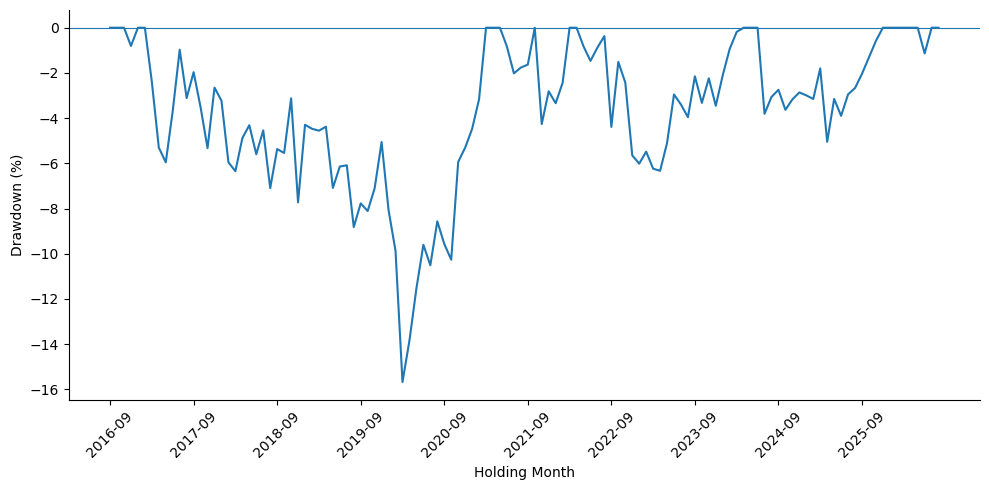

In [77]:
plt.figure(figsize=(10, 5))
plt.plot(portfolio["holding_month"].astype(str), portfolio["drawdown"]*100)
plt.axhline(0, linewidth=0.8)
plt.xticks(
    np.arange(0, len(portfolio), 12),
    portfolio["holding_month"].astype(str).iloc[::12],
    rotation=45
)
plt.ylabel("Drawdown (%)")
plt.xlabel("Holding Month")
plt.tight_layout()
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.savefig(f"{charts_path}/02_drawdown.png", dpi=300, bbox_inches="tight")
plt.show()

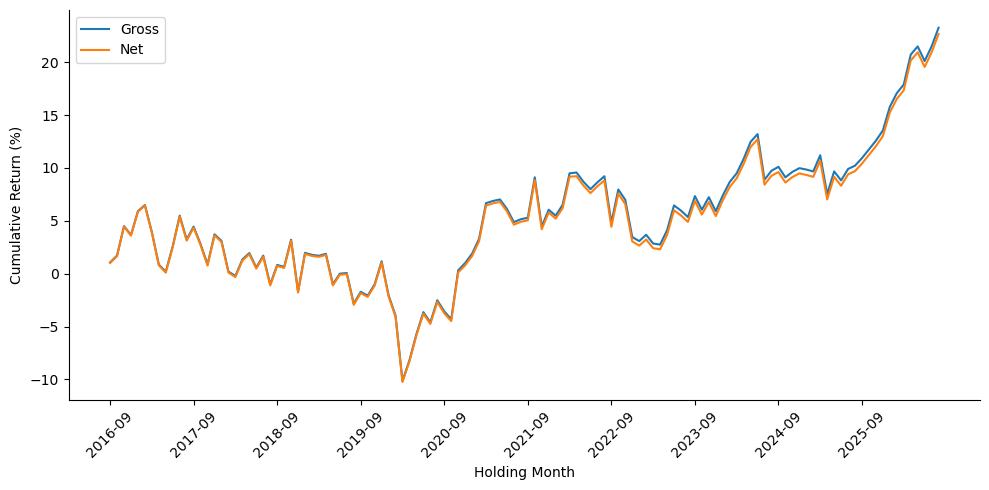

In [78]:
plt.figure(figsize=(10, 5))
plt.plot(portfolio["holding_month"].astype(str), portfolio["cumulative_gross"]*100, label="Gross")
plt.plot(portfolio["holding_month"].astype(str), portfolio["cumulative_net"]*100, label="Net")
plt.xticks(
    np.arange(0, len(portfolio), 12),
    portfolio["holding_month"].astype(str).iloc[::12],
    rotation=45
)
plt.ylabel("Cumulative Return (%)")
plt.xlabel("Holding Month")
plt.legend()
plt.tight_layout()
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.savefig(f"{charts_path}/03_gross_vs_net.png", dpi=300, bbox_inches="tight")
plt.show()

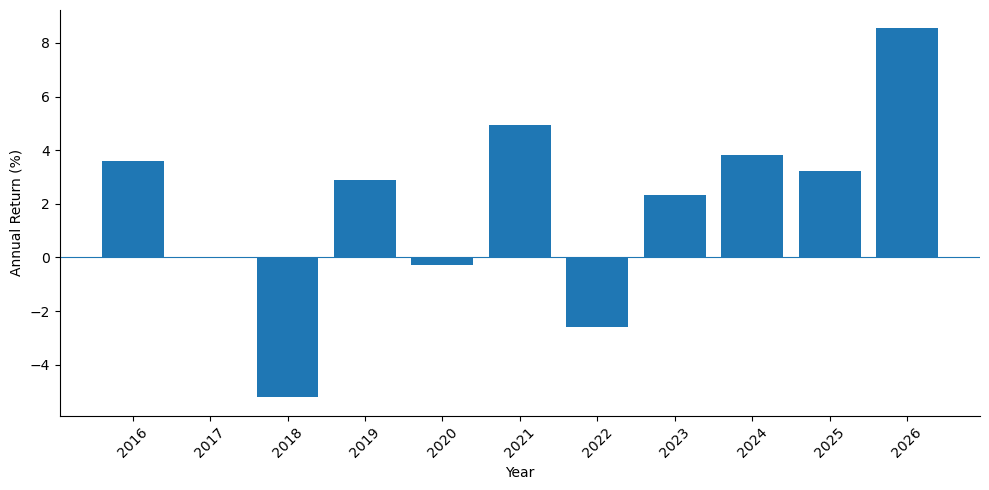

In [79]:
annual_returns = (
    portfolio
    .assign(year=portfolio["holding_month"].dt.year)
    .groupby("year")["long_short_net"]
    .apply(lambda x: (1 + x).prod() - 1)
    .reset_index(name="Annual_Return")
)

annual_returns["Annual_Return"] = annual_returns["Annual_Return"] * 100

plt.figure(figsize=(10, 5))
plt.bar(annual_returns["year"].astype(str), annual_returns["Annual_Return"])
plt.axhline(0, linewidth=0.8)
plt.xticks(rotation=45)
plt.ylabel("Annual Return (%)")
plt.xlabel("Year")
plt.tight_layout()
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.savefig(f"{charts_path}/04_annual_returns.png", dpi=300, bbox_inches="tight")
plt.show()

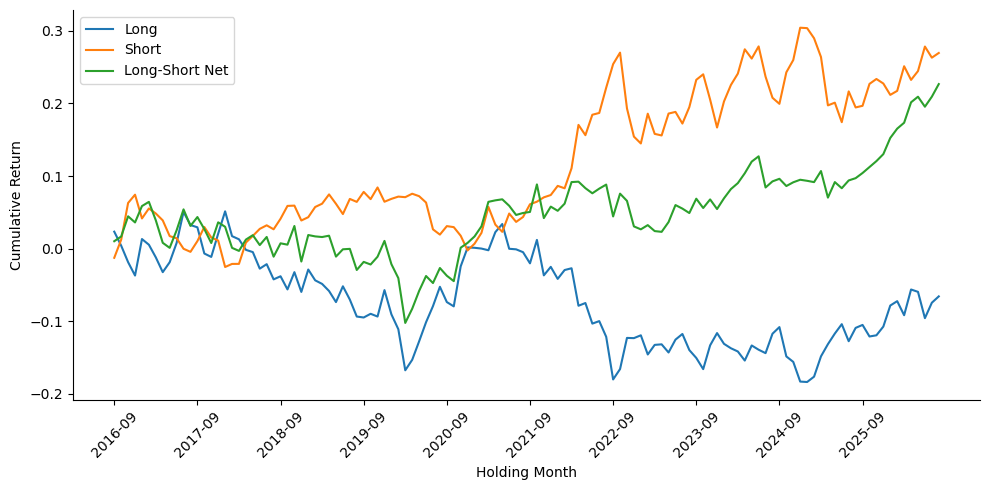

In [80]:
portfolio["cumulative_long"] = (1 + portfolio["long_fx"] + portfolio["long_carry"]).cumprod() - 1
portfolio["cumulative_short"] = (1 - portfolio["short_fx"] - portfolio["short_carry"]).cumprod() - 1

plt.figure(figsize=(10, 5))
plt.plot(portfolio["holding_month"].astype(str), portfolio["cumulative_long"], label="Long")
plt.plot(portfolio["holding_month"].astype(str), portfolio["cumulative_short"], label="Short")
plt.plot(portfolio["holding_month"].astype(str), portfolio["cumulative_net"], label="Long-Short Net")
plt.xticks(
    np.arange(0, len(portfolio), 12),
    portfolio["holding_month"].astype(str).iloc[::12],
    rotation=45
)
plt.ylabel("Cumulative Return")
plt.xlabel("Holding Month")
plt.legend()
plt.tight_layout()
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.savefig(f"{charts_path}/05_long_short_cumulative.png", dpi=300, bbox_inches="tight")
plt.show()

In [82]:
annual_returns.to_csv(
    f"{tables_path}/20_annual_returns.csv",
    index=False
)

print(f"Saved: {tables_path}/20_annual_returns.csv")


Saved: /Users/partha/Documents/FX Carry/outputs/tables1/20_annual_returns.csv


In [84]:
long_frequency = pd.Series(
    [currency for row in portfolio["long_1"] for currency in row]
).value_counts()

short_frequency = pd.Series(
    [currency for row in portfolio["short_1"] for currency in row]
).value_counts()

selection_frequency = pd.DataFrame({
    "Currency": currency_cols,
    "Long_Count": [long_frequency.get(c, 0) for c in currency_cols],
    "Short_Count": [short_frequency.get(c, 0) for c in currency_cols]
})

selection_frequency["Long_Percent"] = selection_frequency["Long_Count"] / len(portfolio) * 100
selection_frequency["Short_Percent"] = selection_frequency["Short_Count"] / len(portfolio) * 100

print(selection_frequency)

selection_frequency.to_csv(
    f"{tables_path}/21_currency_selection_frequency.csv",
    index=False
)

print(f"Saved: {tables_path}/21_currency_selection_frequency.csv")

  Currency  Long_Count  Short_Count  Long_Percent  Short_Percent
0      EUR           0          119      0.000000      99.166667
1      GBP          52            1     43.333333       0.833333
2      JPY           0          119      0.000000      99.166667
3      CHF           0          120      0.000000     100.000000
4      NOK          63            0     52.500000       0.000000
5      AUD          64            0     53.333333       0.000000
6      NZD         100            0     83.333333       0.000000
7      CAD          81            1     67.500000       0.833333
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/21_currency_selection_frequency.csv


In [86]:
long_share = selection_frequency["Long_Count"] / selection_frequency["Long_Count"].sum()
short_share = selection_frequency["Short_Count"] / selection_frequency["Short_Count"].sum()

concentration_results = pd.DataFrame({
    "Side": ["Long", "Short"],
    "HHI": [
        (long_share ** 2).sum(),
        (short_share ** 2).sum()
    ],
    "Effective_Currencies": [
        1 / (long_share ** 2).sum(),
        1 / (short_share ** 2).sum()
    ]
})

print(concentration_results)
concentration_results.to_csv(
    f"{tables_path}/22_selection_concentration.csv",
    index=False
)

print(f"Saved: {tables_path}/22_selection_concentration.csv")

    Side      HHI  Effective_Currencies
0   Long  0.21088              4.742042
1  Short  0.32966              3.033424
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/22_selection_concentration.csv


In [88]:
mean_fx = portfolio["long_short_fx"].mean()
mean_carry = portfolio["long_short_carry"].mean()
mean_gross = portfolio["long_short_gross"].mean()

contribution_results = pd.DataFrame({
    "Component": ["FX", "Interest Carry"],
    "Mean_Monthly_Return": [mean_fx, mean_carry],
    "Contribution_Percent": [
        mean_fx / mean_gross * 100,
        mean_carry / mean_gross * 100
    ]
})

print(contribution_results)
contribution_results.to_csv(
    f"{tables_path}/23_return_contributions.csv",
    index=False
)

print(f"Saved: {tables_path}/23_return_contributions.csv")

        Component  Mean_Monthly_Return  Contribution_Percent
0              FX             0.000173              8.962713
1  Interest Carry             0.001753             91.037287
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/23_return_contributions.csv


In [90]:
long_short_cumulative = portfolio[
    ["holding_month", "cumulative_long", "cumulative_short", "cumulative_net"]
].copy()

long_short_cumulative.to_csv(
    f"{tables_path}/24_long_short_cumulative.csv",
    index=False
)

print(f"Saved: {tables_path}/24_long_short_cumulative.csv")

portfolio.to_csv(
    f"{tables_path}/25_final_portfolio_results.csv",
    index=False
)

print(f"Saved: {tables_path}/25_final_portfolio_results.csv")

Saved: /Users/partha/Documents/FX Carry/outputs/tables1/24_long_short_cumulative.csv
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/25_final_portfolio_results.csv


In [94]:
final_summary = pd.DataFrame({
    "Metric": [
        "Cumulative Return",
        "Annualized Return",
        "Annualized Volatility",
        "Sharpe Ratio",
        "Sortino Ratio",
        "Maximum Drawdown",
        "Best Month",
        "Worst Month",
        "Positive Months",
        "Mean Monthly FX Return",
        "Mean Monthly Carry Return",
        "Mean Monthly Gross Return",
        "Mean Monthly Net Return",
        "Total Transaction Costs"
    ],
    "Value": [
        portfolio["cumulative_net"].iloc[-1] * 100,
        ((1 + portfolio["cumulative_net"].iloc[-1]) ** (12 / len(portfolio)) - 1) * 100,
        portfolio["long_short_net"].std() * np.sqrt(12) * 100,
        portfolio["long_short_net"].mean() / portfolio["long_short_net"].std() * np.sqrt(12),
        portfolio["long_short_net"].mean() / portfolio["long_short_net"][portfolio["long_short_net"] < 0].std() * np.sqrt(12),
        portfolio["drawdown"].min() * 100,
        portfolio["long_short_net"].max() * 100,
        portfolio["long_short_net"].min() * 100,
        (portfolio["long_short_net"] > 0).mean() * 100,
        portfolio["long_short_fx"].mean() * 100,
        portfolio["long_short_carry"].mean() * 100,
        portfolio["long_short_gross"].mean() * 100,
        portfolio["long_short_net"].mean() * 100,
        portfolio["transaction_cost"].sum() * 100
    ]
})

print(final_summary)
final_summary.to_csv(
    f"{tables_path}/26_final_summary.csv",
    index=False
)

print(f"Saved: {tables_path}/26_final_summary.csv")

                       Metric      Value
0           Cumulative Return  22.671759
1           Annualized Return   2.064440
2       Annualized Volatility   6.587957
3                Sharpe Ratio   0.343331
4               Sortino Ratio   0.452655
5            Maximum Drawdown -15.673296
6                  Best Month   4.819803
7                 Worst Month  -6.434640
8             Positive Months  60.000000
9      Mean Monthly FX Return   0.017255
10  Mean Monthly Carry Return   0.175261
11  Mean Monthly Gross Return   0.192515
12    Mean Monthly Net Return   0.188487
13    Total Transaction Costs   0.483333
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/26_final_summary.csv


In [96]:
tail_results = pd.DataFrame({
    "Metric": [
        "5th Percentile",
        "95th Percentile",
        "Downside Deviation",
        "Upside Mean",
        "Downside Mean",
        "Tail Ratio"
    ],
    "Value": [
        portfolio["long_short_net"].quantile(0.05) * 100,
        portfolio["long_short_net"].quantile(0.95) * 100,
        portfolio.loc[portfolio["long_short_net"] < 0, "long_short_net"].std() * 100,
        portfolio.loc[portfolio["long_short_net"] > 0, "long_short_net"].mean() * 100,
        portfolio.loc[portfolio["long_short_net"] < 0, "long_short_net"].mean() * 100,
        abs(portfolio["long_short_net"].quantile(0.95) / portfolio["long_short_net"].quantile(0.05))
    ]
})

print(tail_results.round(3))
tail_results.to_csv(
    f"{tables_path}/27_tail_risk_analysis.csv",
    index=False
)

print(f"Saved: {tables_path}/27_tail_risk_analysis.csv")

               Metric  Value
0      5th Percentile -3.301
1     95th Percentile  2.813
2  Downside Deviation  1.442
3         Upside Mean  1.393
4       Downside Mean -1.618
5          Tail Ratio  0.852
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/27_tail_risk_analysis.csv


In [101]:
yearly_stats = (
    portfolio
    .assign(year=portfolio["holding_month"].dt.year)
    .groupby("year")
    .agg(
        Annual_Return=("long_short_net", lambda x: ((1 + x).prod() - 1) * 100),
        Positive_Months=("long_short_net", lambda x: (x > 0).sum()),
        Negative_Months=("long_short_net", lambda x: (x < 0).sum()),
        Mean_Monthly_Return=("long_short_net", lambda x: x.mean() * 100)
    )
    .reset_index()
)

print(yearly_stats)

yearly_stats.to_csv(
    f"{tables_path}/28_yearly_performance_statistics.csv",
    index=False
)

print(f"Saved: {tables_path}/28_yearly_performance_statistics.csv")

    year  Annual_Return  Positive_Months  Negative_Months  Mean_Monthly_Return
0   2016       3.607911                3                1             0.897890
1   2017       0.013507                6                6             0.023590
2   2018      -5.213022                5                7            -0.423281
3   2019       2.892273                7                5             0.253781
4   2020      -0.264253                6                6             0.021408
5   2021       4.952660                9                3             0.423277
6   2022      -2.577651                6                6            -0.197539
7   2023       2.323776                5                7             0.198177
8   2024       3.826614               10                2             0.323235
9   2025       3.225836                8                4             0.273325
10  2026       8.538803                7                1             1.034406
Saved: /Users/partha/Documents/FX Carry/outputs/tabl

In [103]:
print("Portfolio observations:", len(portfolio))
print("Final cumulative net return:", round(portfolio["cumulative_net"].iloc[-1] * 100, 3), "%")
print("Mean monthly net return:", round(portfolio["long_short_net"].mean() * 100, 3), "%")
print("Maximum drawdown:", round(portfolio["drawdown"].min() * 100, 3), "%")
print("Tables saved:", len(os.listdir(tables_path)))
print("Charts saved:", len(os.listdir(charts_path)))

yearly_stats.to_csv(
    f"{tables_path}/28_yearly_performance_statistics.csv",
    index=False
)

print(f"Saved: {tables_path}/28_yearly_performance_statistics.csv")

Portfolio observations: 120
Final cumulative net return: 22.672 %
Mean monthly net return: 0.188 %
Maximum drawdown: -15.673 %
Tables saved: 28
Charts saved: 5
Saved: /Users/partha/Documents/FX Carry/outputs/tables1/28_yearly_performance_statistics.csv
